# SymptoSense – ML-Based Symptom Triage and Disease Prediction System
AIML Honours reproducible workflow. All displayed metrics are loaded from the executed training report.

## Problem statement
Predict dataset disease labels from reported symptoms using classical ML. Support triage; never replace emergency rules. Not a medical diagnosis.

In [1]:
from pathlib import Path
import sys, json
SERVICE = Path.cwd()
if SERVICE.name == 'notebooks': SERVICE = SERVICE.parent
if SERVICE.name != 'ml-service': SERVICE = SERVICE / 'ml-service'
sys.path.insert(0, str(SERVICE))
from ml_pipeline.data import load_dataset
from ml_pipeline.training import train, pipeline, top3
from IPython.display import display, Image
report = json.loads((SERVICE / 'reports/ml_report.json').read_text())
X, y, symptoms, eda = load_dataset()
print(report['disclaimer'])

C:\Users\dell\Desktop\Sympto\SymptoSense\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Not a medical diagnosis. Consult a qualified healthcare professional. Emergency red flags require immediate medical attention.


## Dataset
The public Kaggle Disease Symptom Prediction CSV supplies disease labels. Severity labels for urgency are explicitly derived proxies. Repeated symptom patterns are removed before splitting.

In [2]:
print(eda['source'], eda['sha256'])
print(X.shape, y.nunique(), eda['source_columns'])

https://www.kaggle.com/datasets/itachi9604/disease-symptom-description-dataset ebbd391c4ba4d64f57a00eb3d0a55f0ca9b920b0c5de6b9af4234e72519c9618
(304, 131) 41 ['Disease', 'Symptom_1', 'Symptom_2', 'Symptom_3', 'Symptom_4', 'Symptom_5', 'Symptom_6', 'Symptom_7', 'Symptom_8', 'Symptom_9', 'Symptom_10', 'Symptom_11', 'Symptom_12', 'Symptom_13', 'Symptom_14', 'Symptom_15', 'Symptom_16', 'Symptom_17']


## EDA
Inspect raw and distinct class counts, empty slots, duplicates, symptom frequencies, correlation and the first ten records.

[{'disease': '(vertigo) Paroymsal  Positional Vertigo',
  'count': 120,
  'unique_count': 7},
 {'disease': 'AIDS', 'count': 120, 'unique_count': 5},
 {'disease': 'Acne', 'count': 120, 'unique_count': 5},
 {'disease': 'Alcoholic hepatitis', 'count': 120, 'unique_count': 8},
 {'disease': 'Allergy', 'count': 120, 'unique_count': 5},
 {'disease': 'Arthritis', 'count': 120, 'unique_count': 6},
 {'disease': 'Bronchial Asthma', 'count': 120, 'unique_count': 7},
 {'disease': 'Cervical spondylosis', 'count': 120, 'unique_count': 6},
 {'disease': 'Chicken pox', 'count': 120, 'unique_count': 10},
 {'disease': 'Chronic cholestasis', 'count': 120, 'unique_count': 8},
 {'disease': 'Common Cold', 'count': 120, 'unique_count': 9},
 {'disease': 'Dengue', 'count': 120, 'unique_count': 10},
 {'disease': 'Diabetes', 'count': 120, 'unique_count': 9},
 {'disease': 'Dimorphic hemmorhoids(piles)', 'count': 120, 'unique_count': 6},
 {'disease': 'Drug Reaction', 'count': 120, 'unique_count': 6},
 {'disease': 'F

[{'column': 'Disease', 'count': 0},
 {'column': 'Symptom_1', 'count': 0},
 {'column': 'Symptom_2', 'count': 0},
 {'column': 'Symptom_3', 'count': 0},
 {'column': 'Symptom_4', 'count': 348},
 {'column': 'Symptom_5', 'count': 1206},
 {'column': 'Symptom_6', 'count': 1986},
 {'column': 'Symptom_7', 'count': 2652},
 {'column': 'Symptom_8', 'count': 2976},
 {'column': 'Symptom_9', 'count': 3228},
 {'column': 'Symptom_10', 'count': 3408},
 {'column': 'Symptom_11', 'count': 3726},
 {'column': 'Symptom_12', 'count': 4176},
 {'column': 'Symptom_13', 'count': 4416},
 {'column': 'Symptom_14', 'count': 4614},
 {'column': 'Symptom_15', 'count': 4680},
 {'column': 'Symptom_16', 'count': 4728},
 {'column': 'Symptom_17', 'count': 4848}]

[{'disease': 'Fungal infection',
  'symptoms': ['dischromic_patches',
   'itching',
   'nodal_skin_eruptions',
   'skin_rash']},
 {'disease': 'Fungal infection',
  'symptoms': ['dischromic_patches', 'nodal_skin_eruptions', 'skin_rash']},
 {'disease': 'Fungal infection',
  'symptoms': ['dischromic_patches', 'itching', 'nodal_skin_eruptions']},
 {'disease': 'Fungal infection',
  'symptoms': ['dischromic_patches', 'itching', 'skin_rash']},
 {'disease': 'Fungal infection',
  'symptoms': ['itching', 'nodal_skin_eruptions', 'skin_rash']},
 {'disease': 'Fungal infection',
  'symptoms': ['dischromic_patches', 'nodal_skin_eruptions', 'skin_rash']},
 {'disease': 'Fungal infection',
  'symptoms': ['dischromic_patches', 'itching', 'nodal_skin_eruptions']},
 {'disease': 'Fungal infection',
  'symptoms': ['dischromic_patches', 'itching', 'skin_rash']},
 {'disease': 'Fungal infection',
  'symptoms': ['itching', 'nodal_skin_eruptions', 'skin_rash']},
 {'disease': 'Fungal infection',
  'symptoms': ['di

Duplicate patterns removed: 4616


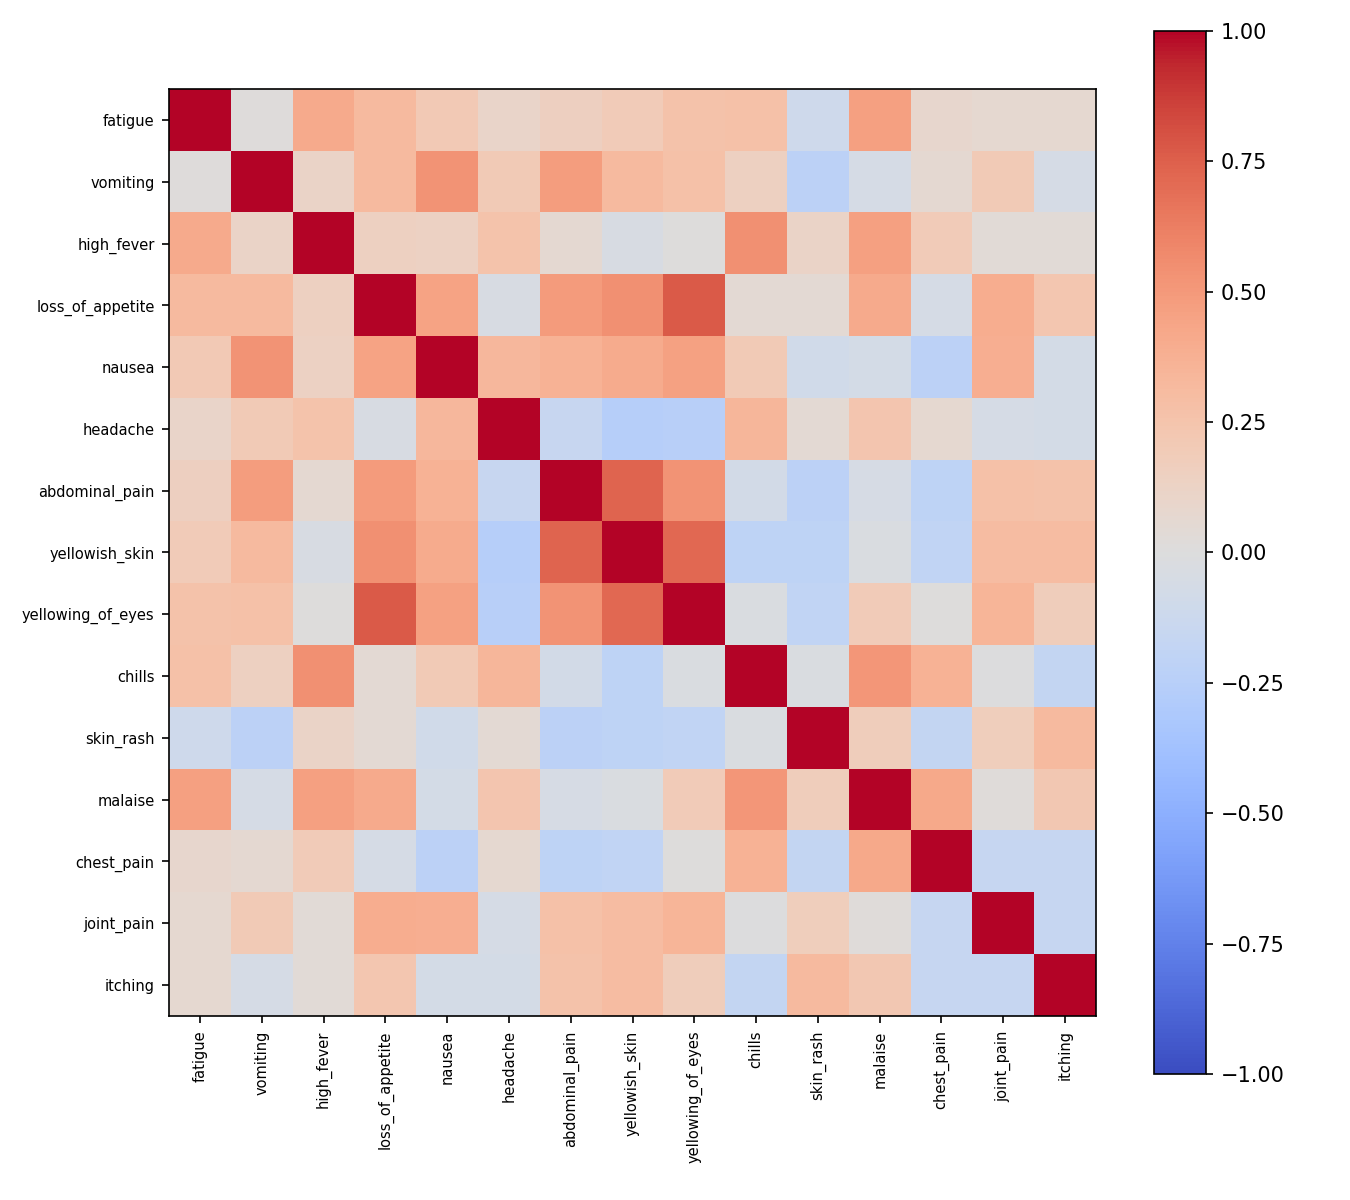

In [3]:
display(eda['class_distribution'])
display(eda['missing_values'])
display(eda['sample'])
print('Duplicate patterns removed:', eda['duplicate_patterns_removed'])
display(Image(filename=str(SERVICE / 'reports/figures/correlation.png')))

## Preprocessing
Slot names become a fixed binary vocabulary. Every learned imputer and scaler lives inside sklearn Pipeline and is fitted within each training fold.

In [4]:
import joblib
best = joblib.load(SERVICE / 'artifacts/best_model.joblib')
display(best)
print(report['split'])

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('impute', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'constant'
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",0
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible. Note that, in the following cases,a new copy will always be made, even if `copy=False`:- If `X` is not an array of floating values;- If `X` is encoded as a CSR matrix;- If `add_indicator=True`.",True
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto outputof the imputer's transform. This allows a predictive estimatorto account for missingness despite imputation. If a feat

{'train_rows': 243, 'test_rows': 61, 'train_indices': [142, 296, 248, 121, 101, 216, 105, 170, 281, 234, 126, 62, 191, 78, 41, 294, 190, 111, 88, 71, 35, 198, 289, 203, 146, 92, 69, 224, 29, 112, 293, 147, 28, 258, 228, 222, 34, 280, 268, 16, 217, 180, 292, 12, 208, 48, 265, 55, 58, 46, 45, 279, 267, 282, 131, 9, 219, 218, 197, 171, 51, 4, 295, 243, 166, 129, 183, 93, 235, 149, 3, 81, 200, 110, 242, 90, 278, 221, 23, 103, 214, 244, 179, 49, 210, 24, 139, 96, 143, 11, 74, 120, 226, 287, 167, 104, 65, 119, 153, 266, 122, 56, 13, 181, 1, 44, 285, 182, 106, 127, 187, 108, 80, 204, 138, 227, 284, 66, 89, 17, 303, 271, 76, 145, 255, 83, 31, 168, 109, 251, 79, 175, 176, 30, 63, 159, 257, 140, 70, 202, 290, 273, 186, 73, 123, 189, 241, 14, 238, 213, 7, 286, 163, 211, 277, 155, 113, 185, 19, 60, 274, 132, 261, 201, 151, 270, 53, 59, 33, 107, 269, 40, 21, 148, 82, 301, 8, 165, 160, 72, 87, 264, 252, 67, 64, 215, 135, 133, 6, 246, 61, 118, 195, 91, 263, 98, 192, 37, 26, 150, 173, 254, 15, 239, 13

## Training and tuning
Compare Logistic Regression, Bernoulli Naive Bayes, Random Forest and XGBoost with seeded five-fold stratification. Search the best two on training folds only. Rare classes limit fold coverage.

In [5]:
# Single executable workflow: train() performs comparison, tuning and evaluation.
# Set RUN_TRAINING=True to regenerate artifacts; defaults to inspecting the completed run.
RUN_TRAINING = False
if RUN_TRAINING: report = train()
display(report['training']['comparison'])
display(report['training']['hyperparameters'])

[{'model': 'Logistic Regression',
  'metrics': {'accuracy': {'mean': 0.9959183673469388,
    'std': 0.008163265306122458,
    'folds': [1.0, 1.0, 0.9795918367346939, 1.0, 1.0]},
   'precision_macro': {'mean': 0.9974999999999999,
    'std': 0.004999999999999982,
    'folds': [1.0, 1.0, 0.9875, 1.0, 1.0]},
   'recall_macro': {'mean': 0.9974999999999999,
    'std': 0.004999999999999982,
    'folds': [1.0, 1.0, 0.9875, 1.0, 1.0]},
   'f1_macro': {'mean': 0.9966666666666667,
    'std': 0.006666666666666731,
    'folds': [1.0, 1.0, 0.9833333333333332, 1.0, 1.0]},
   'top3_accuracy': {'mean': 1.0,
    'std': 0.0,
    'folds': [1.0, 1.0, 1.0, 1.0, 1.0]}}},
 {'model': 'Naive Bayes',
  'metrics': {'accuracy': {'mean': 0.9014455782312926,
    'std': 0.034893383954373254,
    'folds': [0.9183673469387755,
     0.8571428571428571,
     0.8775510204081632,
     0.8958333333333334,
     0.9583333333333334]},
   'precision_macro': {'mean': 0.839258486663814,
    'std': 0.04289626127832967,
    'folds'

[{'model': 'Random Forest',
  'parameters': {'model__max_depth': None, 'model__n_estimators': 100},
  'mean_f1': 1.0,
  'std_f1': 0.0,
  'rank': 1},
 {'model': 'Random Forest',
  'parameters': {'model__max_depth': None, 'model__n_estimators': 200},
  'mean_f1': 1.0,
  'std_f1': 0.0,
  'rank': 1},
 {'model': 'Random Forest',
  'parameters': {'model__max_depth': 8, 'model__n_estimators': 100},
  'mean_f1': 0.9539873879508025,
  'std_f1': 0.03299149838620007,
  'rank': 4},
 {'model': 'Random Forest',
  'parameters': {'model__max_depth': 8, 'model__n_estimators': 200},
  'mean_f1': 0.979991661455076,
  'std_f1': 0.01634525183309907,
  'rank': 3},
 {'model': 'Logistic Regression',
  'parameters': {'model__C': 0.1},
  'mean_f1': 0.9966666666666667,
  'std_f1': 0.006666666666666731,
  'rank': 1},
 {'model': 'Logistic Regression',
  'parameters': {'model__C': 1},
  'mean_f1': 0.9966666666666667,
  'std_f1': 0.006666666666666731,
  'rank': 1},
 {'model': 'Logistic Regression',
  'parameters': {

## Evaluation and calibration
Read held-out confusion matrix, per-class metrics, ROC/AUC and learning curve. Calibration uses supported training-only folds. Compare measured Brier scores rather than assuming calibration helps.

{'accuracy': 1.0,
 'precision_macro': 1.0,
 'recall_macro': 1.0,
 'f1_macro': 1.0,
 'top3_accuracy': 1.0}

[{'disease': '(vertigo) Paroymsal  Positional Vertigo',
  'precision': 1.0,
  'recall': 1.0,
  'f1': 1.0,
  'support': 1},
 {'disease': 'AIDS', 'precision': 1.0, 'recall': 1.0, 'f1': 1.0, 'support': 1},
 {'disease': 'Acne', 'precision': 1.0, 'recall': 1.0, 'f1': 1.0, 'support': 1},
 {'disease': 'Alcoholic hepatitis',
  'precision': 1.0,
  'recall': 1.0,
  'f1': 1.0,
  'support': 2},
 {'disease': 'Allergy',
  'precision': 1.0,
  'recall': 1.0,
  'f1': 1.0,
  'support': 1},
 {'disease': 'Arthritis',
  'precision': 1.0,
  'recall': 1.0,
  'f1': 1.0,
  'support': 1},
 {'disease': 'Bronchial Asthma',
  'precision': 1.0,
  'recall': 1.0,
  'f1': 1.0,
  'support': 1},
 {'disease': 'Cervical spondylosis',
  'precision': 1.0,
  'recall': 1.0,
  'f1': 1.0,
  'support': 1},
 {'disease': 'Chicken pox',
  'precision': 1.0,
  'recall': 1.0,
  'f1': 1.0,
  'support': 2},
 {'disease': 'Chronic cholestasis',
  'precision': 1.0,
  'recall': 1.0,
  'f1': 1.0,
  'support': 2},
 {'disease': 'Common Cold',


Macro AUC: 1.0
Brier before/after: 0.07392459016393443 0.2518052538750228


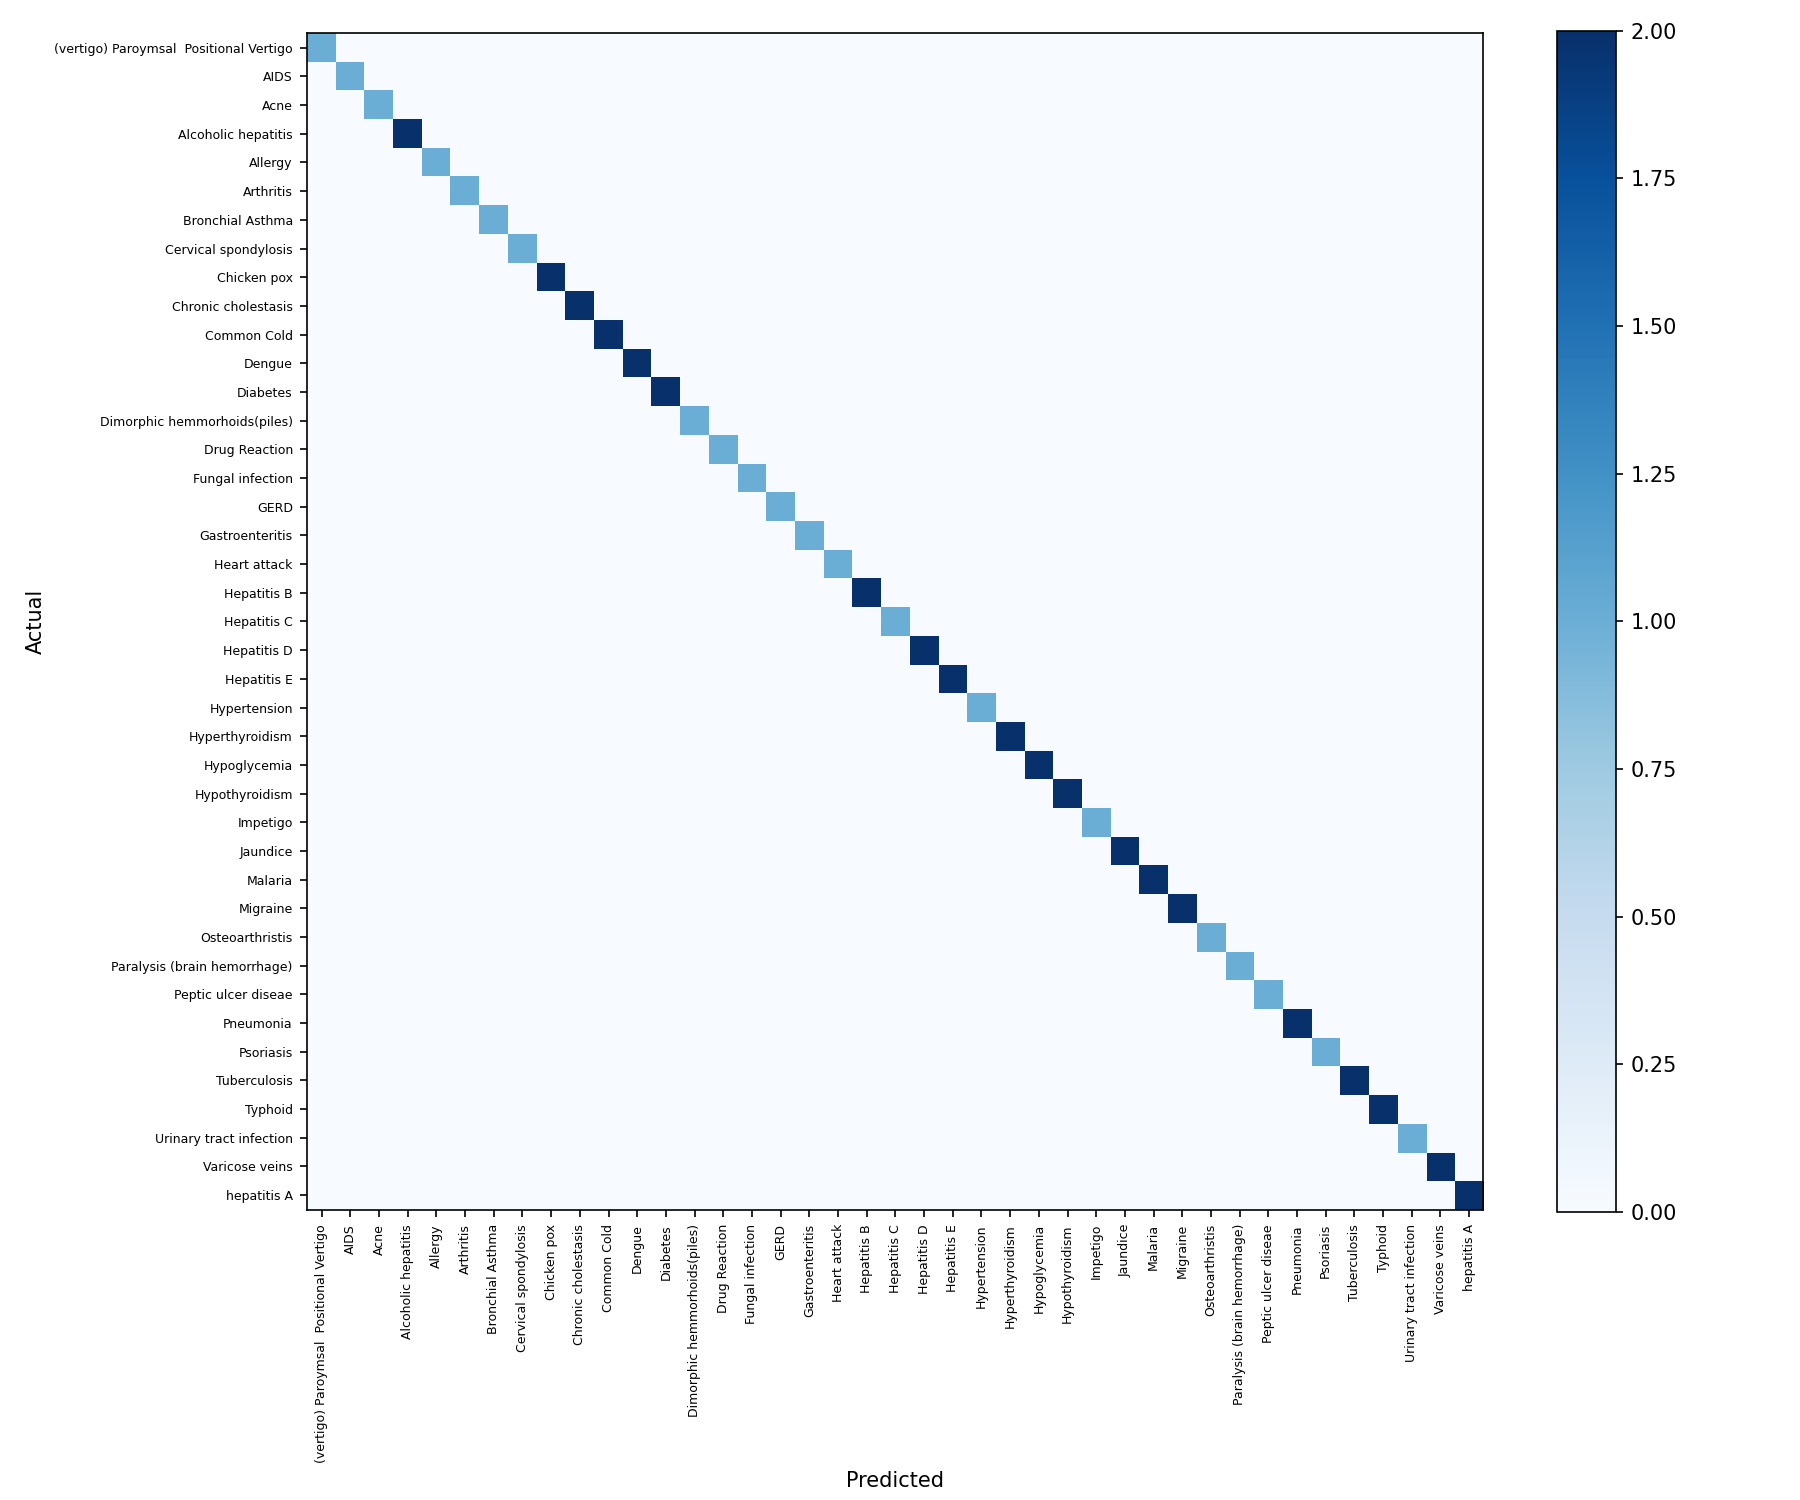

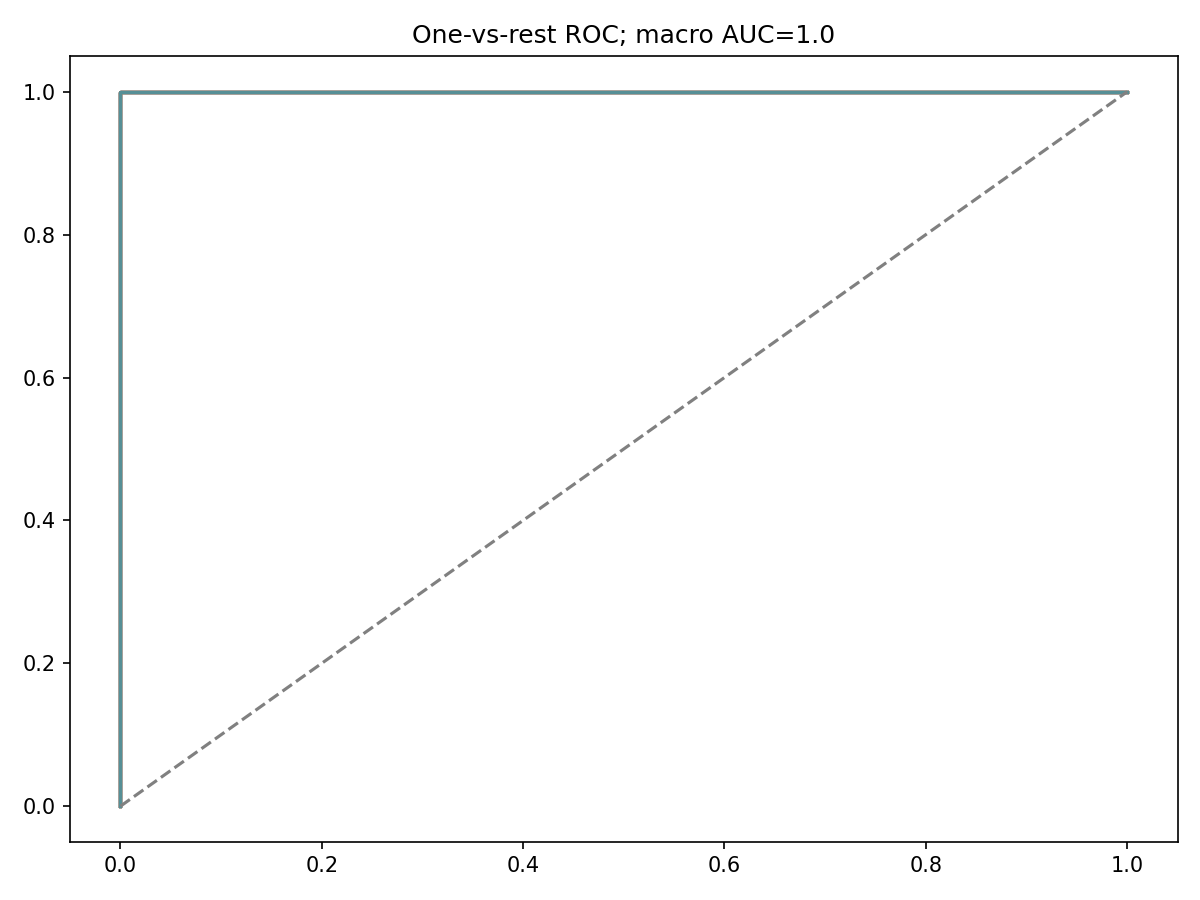

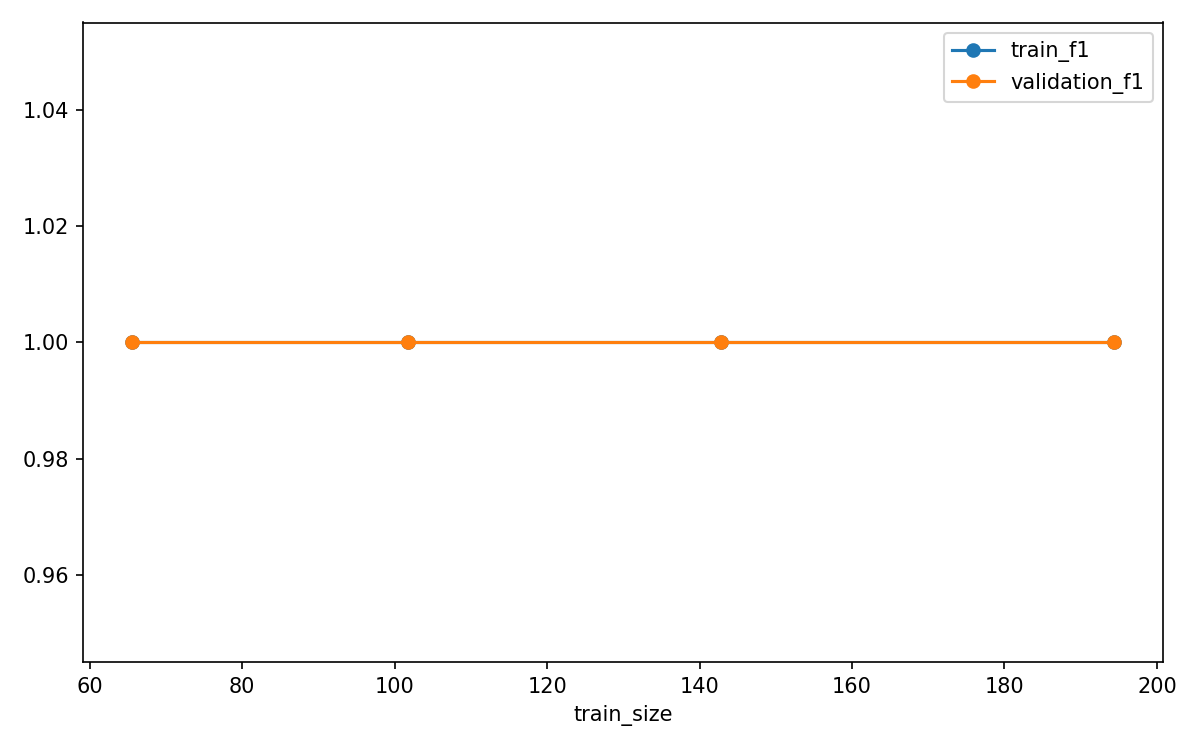

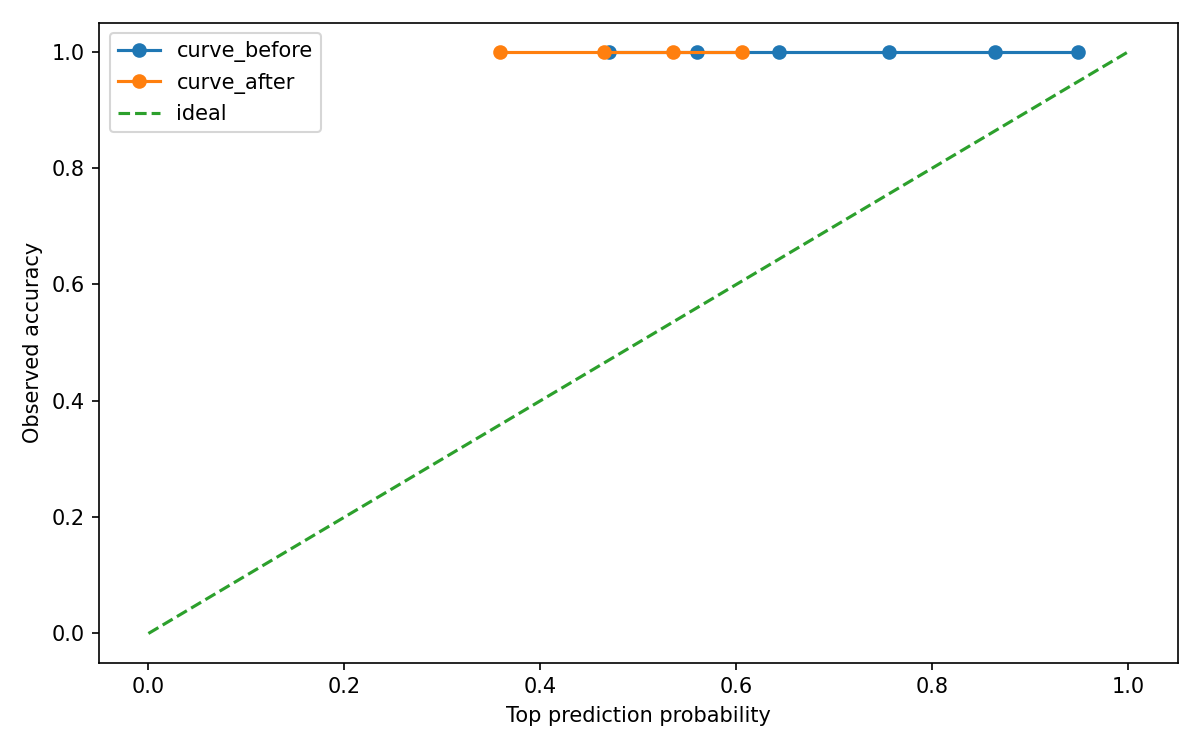

In [6]:
display(report['evaluation']['metrics'])
display(report['evaluation']['per_class'])
print('Macro AUC:', report['evaluation']['macro_auc'])
print('Brier before/after:', report['calibration']['brier_before'], report['calibration']['brier_after'])
for name in ['confusion_matrix', 'roc', 'learning_curve', 'calibration']:
    display(Image(filename=str(SERVICE / ('reports/figures/' + name + '.png'))))

## Robustness and SHAP
Drop active symptoms using seeded Bernoulli trials. Permutation SHAP explains the calibrated model probability; present and absent symptoms can contribute.

[{'symptom': 'receiving_blood_transfusion',
  'contribution': 0.10563777300081045,
  'present': True},
 {'symptom': 'receiving_unsterile_injections',
  'contribution': 0.07917944548304187,
  'present': True},
 {'symptom': 'malaise', 'contribution': 0.055073512946609046, 'present': True},
 {'symptom': 'lethargy', 'contribution': 0.03142440981434971, 'present': True},
 {'symptom': 'dark_urine',
  'contribution': 0.025573355831531704,
  'present': True}]

[{'percent_dropped': 0,
  'accuracy': 1.0,
  'std': 0.0,
  'repeats': [1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]},
 {'percent_dropped': 10,
  'accuracy': 0.9934426229508198,
  'std': 0.008031113910764527,
  'repeats': [1.0,
   0.9836065573770492,
   1.0,
   0.9836065573770492,
   1.0,
   1.0,
   0.9836065573770492,
   1.0,
   1.0,
   0.9836065573770492]},
 {'percent_dropped': 20,
  'accuracy': 0.9737704918032787,
  'std': 0.019672131147540982,
  'repeats': [0.9672131147540983,
   0.9836065573770492,
   0.9344262295081968,
   1.0,
   0.9836065573770492,
   1.0,
   0.9672131147540983,
   0.9672131147540983,
   0.9836065573770492,
   0.9508196721311475]},
 {'percent_dropped': 30,
  'accuracy': 0.9459016393442623,
  'std': 0.030272434938720293,
  'repeats': [0.9836065573770492,
   0.9672131147540983,
   0.8852459016393442,
   0.9672131147540983,
   0.9672131147540983,
   0.9508196721311475,
   0.9672131147540983,
   0.9344262295081968,
   0.9344262295081968,
   0.9016393442622951]}

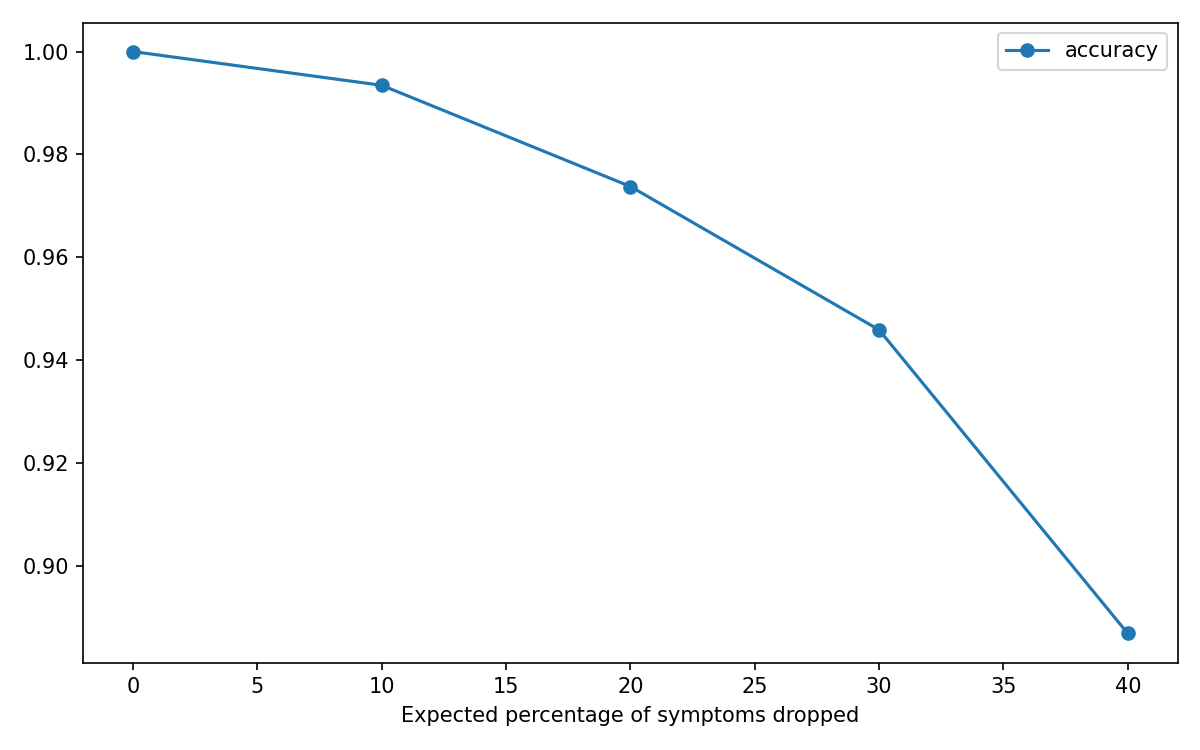

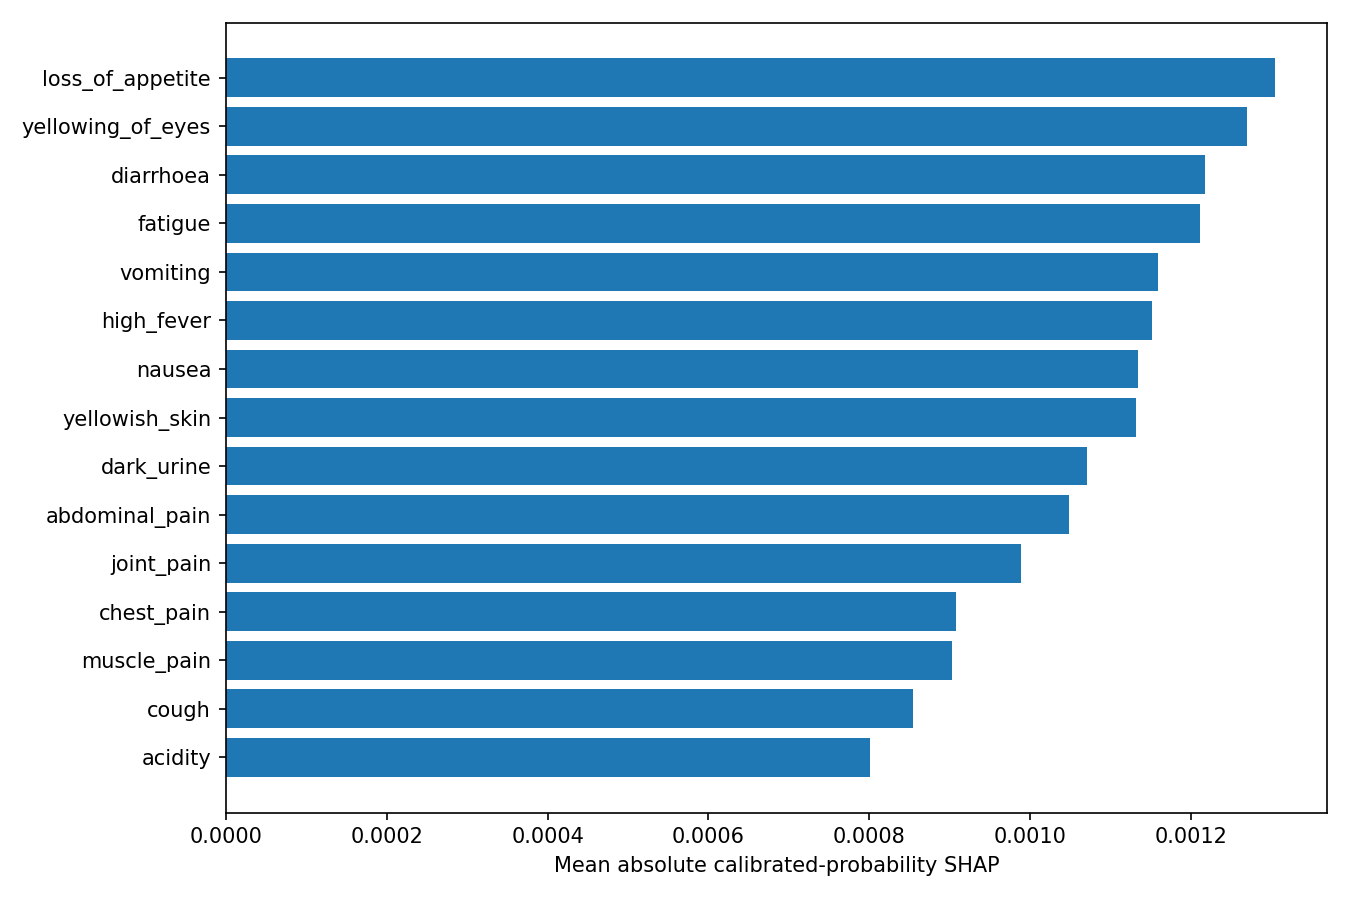

In [7]:
from ml_pipeline.explain import explain_input
calibrated = joblib.load(SERVICE / 'artifacts/calibrated_model.joblib')
background = joblib.load(SERVICE / 'artifacts/shap_background.joblib')
vector = X.iloc[report['split']['test_indices'][0]].to_numpy()
label = calibrated.predict_proba(vector.reshape(1, -1))[0].argmax()
display(explain_input(calibrated, background, symptoms, vector, int(label)))
display(report['evaluation']['robustness'])
for name in ['robustness', 'shap_global']:
    display(Image(filename=str(SERVICE / ('reports/figures/' + name + '.png'))))

## Urgency and limitations
Urgency targets are training-derived disease mean symptom-weight terciles. Agreement uses the actual TypeScript rule engine under a documented fixed context. Dataset accuracy is not clinical diagnostic accuracy.

In [8]:
display(report['urgency'])
for limitation in report['limitations']: print('-', limitation)

{'labels': ['Low', 'Medium', 'High'],
 'severity_file': 'Symptom-severity.csv',
 'severity_sha256': 'cb5a84b5ebde81bb18738b7e7733bcbc5abdc667b4376893fb1774d8c444bc8d',
 'severity_aliases': {'foul_smell_of_urine': 'foul_smell_ofurine'},
 'duplicate_severity_entries': [{'symptom': 'fluid_overload', 'weight': 6},
  {'symptom': 'fluid_overload', 'weight': 4}],
 'duplicate_weight_policy': 'Mean of supplied weights for repeated normalized symptom names (fluid_overload has 6 and 4, mean 5)',
 'label_source': 'Disease mean symptom severity from TRAINING rows; relative disease-weight terciles, not clinician urgency labels',
 'thresholds': [3.949175824175824, 4.526213818860878],
 'disease_weights': [{'disease': '(vertigo) Paroymsal  Positional Vertigo',
   'weight': 4.516666666666667,
   'urgency': 'Medium'},
  {'disease': 'AIDS', 'weight': 5.229166666666667, 'urgency': 'High'},
  {'disease': 'Acne', 'weight': 2.229166666666667, 'urgency': 'Low'},
  {'disease': 'Alcoholic hepatitis',
   'weight'

- Public symptom-disease associations are not independently verified patient records; dataset does not establish clinical diagnostic accuracy.
- Only 304 unique patterns remain after deduplication; held-out support is small and results do not establish external generalization.
- The least-populated training classes have fewer than five rows: 5-fold stratification is approximate and some validation folds omit rare classes. Calibration uses the supported fold count.
- Hyperparameter search and model selection share training CV folds; CV scores are selection estimates, while the held-out test is used only after selection.
- Urgency labels are derived relative severity proxies; clinical urgency is not supervised by clinician labels. Red-flag rules always override to High.
- Age, duration and reported intensity are absent from the disease dataset and are not disease-model features; rule triage uses the available context.
- SHAP is a seeded sampling estimate, includes absent symptoms, and de